# Transformers — Notebook 03
## Transformer básico desde cero para pronóstico de series de tiempo

Se implementan, con capas propias de Keras, los componentes de *Attention Is All You Need* (Vaswani et al., 2017) y se adaptan a la serie de temperatura:

| Componente del paper | Implementación aquí | Papel en la serie de tiempo |
|---|---|---|
| *Input embedding* | `Dense(d_model)` sobre [temp, sin, cos] de cada día | Proyecta cada día a un vector de dimensión d_model = 32 |
| Codificación posicional | `PositionalEncoding` sinusoidal | Indica a la atención **en qué posición** de la ventana está cada día |
| Scaled dot-product attention | `scaled_dot_product_attention` | Compara cada día con todos los demás |
| Multi-head attention | `MultiHeadAttentionScratch` (4 cabezas, d_k = 8) | Varias «miradas» simultáneas (p. ej. días recientes, tendencia) |
| Add & Norm + Feed-forward | `EncoderBlock` | Conexiones residuales, LayerNorm y red densa por posición |
| Decodificador con máscara causal | `DecoderBlock` | Genera los 7 días uno a uno sin mirar el futuro |

Modelos entrenados:
* **Transformer-Encoder** (2 bloques): codifica los 60 días y una capa densa produce los 7 pronósticos a la vez.
* **Transformer-Encoder sin codificación posicional** (ablación).
* **Transformer Encoder-Decoder** (2 + 1 bloques): arquitectura completa del paper con *teacher forcing* en el entrenamiento y generación autorregresiva en la prueba.

In [1]:
import os, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
"""Utilidades de series de tiempo: carga, partición cronológica, escalado, ventanas, líneas base y métricas."""
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
LOOKBACK = 60          # días de contexto que ve el modelo
HORIZON = 7            # días a pronosticar
SPLITS = {"train": ("1981-01-01", "1986-12-31"), "val": ("1987-01-01", "1988-12-31"), "test": ("1989-01-01", "1990-12-31")}

for d in ("data", "figures", "results", "modelos"):
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load_series(path: str = "data/daily-min-temperatures.csv") -> pd.Series:
    """Temperatura mínima diaria de Melbourne (°C), con frecuencia diaria completa."""
    if not os.path.exists(path):
        pd.read_csv(URL).to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["Date"])
    s = pd.to_numeric(df["Temp"], errors="coerce")
    s.index = df["Date"]
    full = s.asfreq("D")                       # inserta las fechas faltantes como NaN
    return full


def calendar_features(index: pd.DatetimeIndex) -> np.ndarray:
    """Codificación cíclica del día del año: (sin, cos). Evita el salto artificial 31-dic → 1-ene."""
    doy = index.dayofyear.values
    ang = 2 * np.pi * doy / 365.25
    return np.stack([np.sin(ang), np.cos(ang)], axis=1).astype("float32")


class Scaler:
    """Estandarización z-score ajustada SÓLO con el conjunto de entrenamiento."""
    def fit(self, x):
        self.mu, self.sigma = float(np.mean(x)), float(np.std(x)); return self
    def transform(self, x): return (np.asarray(x) - self.mu) / self.sigma
    def inverse(self, z): return np.asarray(z) * self.sigma + self.mu


def make_windows(values_z, feats, dates, start, end, lookback=LOOKBACK, horizon=HORIZON):
    """Ventanas deslizantes: X = [temp_z, sin, cos] de los `lookback` días previos,
    y = temp_z de los `horizon` días siguientes. Sólo se aceptan ventanas cuyo PRIMER día
    a pronosticar cae en [start, end] y cuyo último día objetivo no supera `end`
    (el contexto sí puede venir del periodo anterior, que ya es pasado conocido)."""
    X_in = np.concatenate([values_z[:, None], feats], axis=1).astype("float32")
    t0 = np.searchsorted(dates, np.datetime64(start)); t1 = np.searchsorted(dates, np.datetime64(end), side="right")
    X, Y, D, F = [], [], [], []
    for t in range(max(t0, lookback), t1 - horizon + 1):
        X.append(X_in[t - lookback:t]); Y.append(values_z[t:t + horizon])
        F.append(feats[t:t + horizon]); D.append(dates[t])
    return np.array(X), np.array(Y, dtype="float32"), np.array(F, dtype="float32"), np.array(D)


def prepare(lookback=LOOKBACK, horizon=HORIZON):
    """Pipeline completo: serie limpia, escalador y ventanas por partición."""
    s = load_series()
    n_missing = int(s.isna().sum())
    s = s.interpolate(limit_direction="both")
    dates = s.index.values
    tr_mask = (s.index >= SPLITS["train"][0]) & (s.index <= SPLITS["train"][1])
    scaler = Scaler().fit(s.values[tr_mask])
    z = scaler.transform(s.values).astype("float32")
    feats = calendar_features(s.index)
    data = {"series": s, "scaler": scaler, "n_missing": n_missing, "z": z, "feats": feats}
    for name, (a, b) in SPLITS.items():
        X, Y, F, D = make_windows(z, feats, dates, a, b, lookback, horizon)
        data[name] = {"X": X, "Y": Y, "F": F, "dates": D}
    return data


# ----------------------------------------------------------------------------- líneas base
def persistence(X):
    """Pronóstico ingenuo: los próximos días serán iguales al último observado."""
    return np.repeat(X[:, -1:, 0], HORIZON, axis=1)


def climatology_model(series: pd.Series, scaler: Scaler, window: int = 15):
    """Media por día del año en train (suavizada con media móvil circular). Devuelve f(fechas)->z."""
    tr = series[SPLITS["train"][0]:SPLITS["train"][1]]
    clim = tr.groupby(tr.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    ext = pd.concat([clim.iloc[-window:], clim, clim.iloc[:window]])
    smooth = ext.rolling(window, center=True).mean().iloc[window:-window]
    def predict(first_dates):
        out = []
        for d0 in pd.to_datetime(first_dates):
            days = pd.date_range(d0, periods=HORIZON, freq="D").dayofyear
            out.append(scaler.transform(smooth.loc[days].values))
        return np.array(out, dtype="float32")
    return predict, smooth


# ----------------------------------------------------------------------------- métricas
def metrics(y_true_z, y_pred_z, scaler: Scaler) -> dict:
    """MAE y RMSE en °C (global y por horizonte)."""
    yt, yp = scaler.inverse(y_true_z), scaler.inverse(y_pred_z)
    err = yp - yt
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
            "MAE_h": np.abs(err).mean(0).tolist(), "MAE_d1": float(np.abs(err[:, 0]).mean()),
            "MAE_d7": float(np.abs(err[:, -1]).mean())}


def save_json(obj, path):
    def conv(o):
        if isinstance(o, (np.floating, np.integer)): return o.item()
        if isinstance(o, np.ndarray): return o.tolist()
        return str(o)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=conv)


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

In [3]:
"""Mecanismos de atención y bloques Transformer implementados desde cero en Keras 3 (backend TensorFlow).

Referencia: Vaswani et al. (2017), "Attention Is All You Need".
"""
import numpy as np
import tensorflow as tf
import keras
from keras import layers, ops


# ============================================================================ atención básica
def scaled_dot_product_attention(q, k, v, mask=None):
    """Attention(Q, K, V) = softmax(Q·Kᵀ / √d_k + máscara) · V      (ecuación 1 del paper)

    q: (..., Tq, d_k)  k: (..., Tk, d_k)  v: (..., Tk, d_v)
    mask: 1 = posición permitida, 0 = bloqueada; se suma -1e9 a las bloqueadas antes del softmax.
    Devuelve (salida (..., Tq, d_v), pesos de atención (..., Tq, Tk)).
    """
    d_k = ops.cast(ops.shape(k)[-1], q.dtype)
    scores = ops.matmul(q, ops.swapaxes(k, -1, -2)) / ops.sqrt(d_k)
    if mask is not None:
        scores = scores + (1.0 - ops.cast(mask, scores.dtype)) * -1e9
    weights = ops.softmax(scores, axis=-1)
    return ops.matmul(weights, v), weights


def causal_mask(T):
    """Máscara triangular inferior: la posición t sólo puede atender a posiciones ≤ t."""
    return np.tril(np.ones((T, T), dtype="float32"))


@keras.saving.register_keras_serializable(package="tst")
class AdditiveAttention(layers.Layer):
    """Atención aditiva de Bahdanau sobre los estados ocultos de un codificador recurrente.

    e_t = vᵀ tanh(W₁ h_t + W₂ s),  α = softmax(e),  c = Σ_t α_t h_t
    donde h_t son los estados del LSTM en cada día y s es el último estado (la "consulta").
    """
    def __init__(self, units=32, **kw):
        super().__init__(**kw); self.units = units
        self.W1 = layers.Dense(units, use_bias=False)
        self.W2 = layers.Dense(units, use_bias=True)
        self.v = layers.Dense(1, use_bias=False)

    def call(self, states, query):
        score = self.v(ops.tanh(self.W1(states) + ops.expand_dims(self.W2(query), 1)))   # (B, T, 1)
        alpha = ops.softmax(score, axis=1)
        context = ops.sum(alpha * states, axis=1)                                         # (B, units_lstm)
        return context, ops.squeeze(alpha, -1)

    def get_config(self):
        return {**super().get_config(), "units": self.units}


# ============================================================================ Transformer
@keras.saving.register_keras_serializable(package="tst")
class PositionalEncoding(layers.Layer):
    """Codificación posicional sinusoidal (sección 3.5 del paper):
    PE(pos, 2i) = sin(pos / 10000^(2i/d)),  PE(pos, 2i+1) = cos(pos / 10000^(2i/d)).
    Se SUMA al embedding: la atención por sí sola no conoce el orden temporal."""
    def __init__(self, max_len=512, d_model=32, **kw):
        super().__init__(**kw); self.max_len, self.d_model = max_len, d_model
        pos = np.arange(max_len)[:, None]
        i = np.arange(d_model)[None, :]
        angle = pos / np.power(10000.0, (2 * (i // 2)) / d_model)
        pe = np.zeros((max_len, d_model), dtype="float32")
        pe[:, 0::2], pe[:, 1::2] = np.sin(angle[:, 0::2]), np.cos(angle[:, 1::2])
        self.pe = pe

    def call(self, x):
        T = ops.shape(x)[1]
        return x + ops.convert_to_tensor(self.pe)[None, :T, :]

    def get_config(self):
        return {**super().get_config(), "max_len": self.max_len, "d_model": self.d_model}


@keras.saving.register_keras_serializable(package="tst")
class MultiHeadAttentionScratch(layers.Layer):
    """Multi-head attention (sección 3.2.2):
    MultiHead(Q,K,V) = Concat(head₁..head_h)·Wᴼ,   head_i = Attention(Q·Wᵢ^Q, K·Wᵢ^K, V·Wᵢ^V).
    Las h cabezas trabajan en paralelo en subespacios de dimensión d_k = d_model / h."""
    def __init__(self, d_model=32, num_heads=4, **kw):
        super().__init__(**kw)
        assert d_model % num_heads == 0, "d_model debe ser divisible por num_heads"
        self.d_model, self.h, self.d_k = d_model, num_heads, d_model // num_heads
        self.wq, self.wk, self.wv = (layers.Dense(d_model, name=n) for n in ("wq", "wk", "wv"))
        self.wo = layers.Dense(d_model, name="wo")

    def _split(self, x):                       # (B, T, d_model) -> (B, h, T, d_k)
        B, T = ops.shape(x)[0], ops.shape(x)[1]
        return ops.transpose(ops.reshape(x, (B, T, self.h, self.d_k)), (0, 2, 1, 3))

    def call(self, query, value, key=None, mask=None, return_attention_scores=False):
        key = value if key is None else key
        q, k, v = self._split(self.wq(query)), self._split(self.wk(key)), self._split(self.wv(value))
        out, w = scaled_dot_product_attention(q, k, v, mask)           # (B, h, Tq, d_k), (B, h, Tq, Tk)
        B, Tq = ops.shape(out)[0], ops.shape(out)[2]
        out = self.wo(ops.reshape(ops.transpose(out, (0, 2, 1, 3)), (B, Tq, self.d_model)))
        return (out, w) if return_attention_scores else out

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "num_heads": self.h}


@keras.saving.register_keras_serializable(package="tst")
class EncoderBlock(layers.Layer):
    """Capa del codificador: self-attention multi-cabeza + Add & Norm + red feed-forward + Add & Norm."""
    def __init__(self, d_model=32, num_heads=4, d_ff=64, dropout=0.1, **kw):
        super().__init__(**kw)
        self.cfg = dict(d_model=d_model, num_heads=num_heads, d_ff=d_ff, dropout=dropout)
        self.mha = MultiHeadAttentionScratch(d_model, num_heads)
        self.ffn = keras.Sequential([layers.Dense(d_ff, activation="relu"), layers.Dense(d_model)])
        self.norm1, self.norm2 = layers.LayerNormalization(epsilon=1e-6), layers.LayerNormalization(epsilon=1e-6)
        self.drop1, self.drop2 = layers.Dropout(dropout), layers.Dropout(dropout)

    def call(self, x, training=False, mask=None, return_attention=False):
        a, w = self.mha(x, x, mask=mask, return_attention_scores=True)
        x = self.norm1(x + self.drop1(a, training=training))                 # residual + LayerNorm
        x = self.norm2(x + self.drop2(self.ffn(x), training=training))
        return (x, w) if return_attention else x

    def get_config(self):
        return {**super().get_config(), **self.cfg}


@keras.saving.register_keras_serializable(package="tst")
class DecoderBlock(layers.Layer):
    """Capa del decodificador: self-attention ENMASCARADA (causal) + atención cruzada al codificador + FFN."""
    def __init__(self, d_model=32, num_heads=4, d_ff=64, dropout=0.1, **kw):
        super().__init__(**kw)
        self.cfg = dict(d_model=d_model, num_heads=num_heads, d_ff=d_ff, dropout=dropout)
        self.self_mha = MultiHeadAttentionScratch(d_model, num_heads)
        self.cross_mha = MultiHeadAttentionScratch(d_model, num_heads)
        self.ffn = keras.Sequential([layers.Dense(d_ff, activation="relu"), layers.Dense(d_model)])
        self.n1, self.n2, self.n3 = (layers.LayerNormalization(epsilon=1e-6) for _ in range(3))
        self.d1, self.d2, self.d3 = (layers.Dropout(dropout) for _ in range(3))

    def call(self, y, enc, training=False, return_attention=False):
        T = ops.shape(y)[1]
        mask = ops.tril(ops.ones((T, T)))                                  # causal: no mira el futuro
        a, w_self = self.self_mha(y, y, mask=mask, return_attention_scores=True)
        y = self.n1(y + self.d1(a, training=training))
        c, w_cross = self.cross_mha(y, enc, return_attention_scores=True)  # Q del decoder, K y V del encoder
        y = self.n2(y + self.d2(c, training=training))
        y = self.n3(y + self.d3(self.ffn(y), training=training))
        return (y, w_self, w_cross) if return_attention else y

    def get_config(self):
        return {**super().get_config(), **self.cfg}

In [4]:
keras.utils.set_random_seed(SEED)
data = prepare()
scaler = data["scaler"]
Xtr, Ytr, Ftr = (data["train"][k] for k in ("X", "Y", "F"))
Xva, Yva, Fva = (data["val"][k] for k in ("X", "Y", "F"))
Xte, Yte, Fte = (data["test"][k] for k in ("X", "Y", "F"))
D_MODEL, HEADS, D_FF, DROPOUT = 32, 4, 64, 0.1

## 1. Codificación posicional
La self-attention es **invariante a permutaciones**: si se barajan los 60 días, cada salida es la misma combinación ponderada. Para que el modelo distinga «ayer» de «hace 50 días» se suma a cada embedding un vector que depende sólo de la posición, construido con senos y cosenos de distintas frecuencias:

$$PE_{(pos,2i)} = \sin\!\left(pos / 10000^{2i/d_{model}}\right),\qquad PE_{(pos,2i+1)} = \cos\!\left(pos / 10000^{2i/d_{model}}\right)$$

Las dimensiones bajas oscilan rápido (resolución fina) y las altas lento (posición gruesa); además, $PE_{pos+k}$ es una función lineal de $PE_{pos}$, lo que facilita aprender relaciones de rezago relativo.

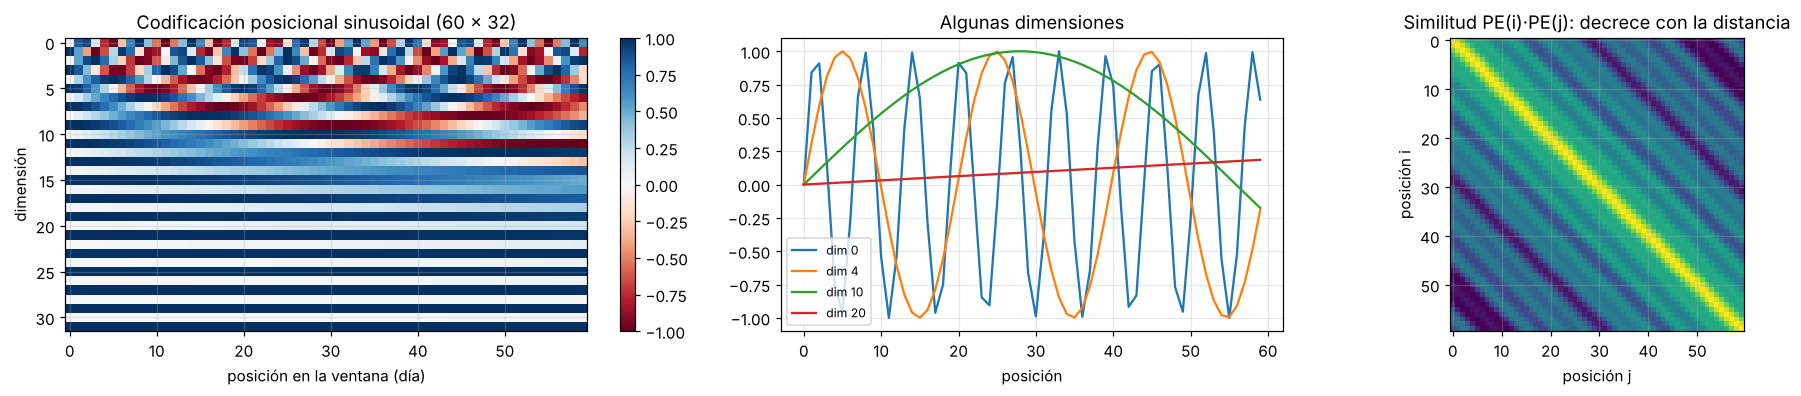

In [5]:
pe = PositionalEncoding(LOOKBACK, D_MODEL).pe
fig, ax = plt.subplots(1, 3, figsize=(17, 3.7), gridspec_kw={"width_ratios": [1.3, 1, 1]})
im = ax[0].imshow(pe.T, aspect="auto", cmap="RdBu"); ax[0].set_xlabel("posición en la ventana (día)"); ax[0].set_ylabel("dimensión")
ax[0].set_title("Codificación posicional sinusoidal (60 × 32)"); plt.colorbar(im, ax=ax[0])
for i in [0, 4, 10, 20]:
    ax[1].plot(pe[:, i], label=f"dim {i}")
ax[1].set_title("Algunas dimensiones"); ax[1].set_xlabel("posición"); ax[1].legend(fontsize=8)
sim = pe @ pe.T
ax[2].imshow(sim, cmap="viridis"); ax[2].set_title("Similitud PE(i)·PE(j): decrece con la distancia"); ax[2].set_xlabel("posición j"); ax[2].set_ylabel("posición i")
plt.tight_layout(); plt.savefig("figures/03_codificacion_posicional.png", bbox_inches="tight"); plt.show()

## 2. Verificación de la multi-head attention propia
Se copian los pesos de `MultiHeadAttentionScratch` a la capa oficial `keras.layers.MultiHeadAttention` y se comparan las salidas para la misma entrada.

In [6]:
x = np.random.default_rng(0).normal(size=(4, LOOKBACK, D_MODEL)).astype("float32")
mine = MultiHeadAttentionScratch(D_MODEL, HEADS)
out_mine, w_mine = mine(x, x, return_attention_scores=True)
ref = layers.MultiHeadAttention(num_heads=HEADS, key_dim=D_MODEL // HEADS); ref(x, x)
for nm, dense in zip(["query", "key", "value"], [mine.wq, mine.wk, mine.wv]):
    W, b = dense.get_weights()
    getattr(ref, f"_{nm}_dense").set_weights([W.reshape(D_MODEL, HEADS, -1), b.reshape(HEADS, -1)])
W, b = mine.wo.get_weights(); ref._output_dense.set_weights([W.reshape(HEADS, -1, D_MODEL), b])
out_ref, w_ref = ref(x, x, return_attention_scores=True)
print(f"Diferencia máxima en la salida: {np.abs(np.array(out_mine) - np.array(out_ref)).max():.2e}")
print(f"Diferencia máxima en los pesos de atención: {np.abs(np.array(w_mine) - np.array(w_ref)).max():.2e}")
print("Forma de los pesos de atención (batch, cabezas, consultas, claves):", tuple(w_mine.shape),
      "| suma por fila:", float(np.array(w_mine).sum(-1).mean()))

Diferencia máxima en la salida: 3.58e-07
Diferencia máxima en los pesos de atención: 1.79e-07
Forma de los pesos de atención (batch, cabezas, consultas, claves): (4, 4, 60, 60) | suma por fila: 1.0


## 3. Transformer-Encoder

In [7]:
def build_encoder_model(use_pe=True, n_layers=2, name="Transformer_Encoder"):
    inp = keras.Input((LOOKBACK, 3), name="ventana")
    h = layers.Dense(D_MODEL, name="embedding")(inp)                       # embedding de entrada
    if use_pe:
        h = PositionalEncoding(LOOKBACK, D_MODEL, name="codificacion_posicional")(h)
    h = layers.Dropout(DROPOUT)(h)
    atts = []
    for i in range(n_layers):
        h, w = EncoderBlock(D_MODEL, HEADS, D_FF, DROPOUT, name=f"encoder_{i + 1}")(h, return_attention=True)
        atts.append(w)
    z = layers.Concatenate()([h[:, -1, :], layers.GlobalAveragePooling1D()(h)])   # último día + resumen global
    out = layers.Dense(HORIZON, name="pronostico")(layers.Dropout(DROPOUT)(layers.Dense(64, activation="relu")(z)))
    return keras.Model(inp, out, name=name), keras.Model(inp, atts)

def fit(model, X, Y, Xv, Yv, epochs=200, lr=1e-3, batch=64):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse", metrics=["mae"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5)]
    t0 = time.time()
    h = model.fit(X, Y, validation_data=(Xv, Yv), epochs=epochs, batch_size=batch, callbacks=cb, verbose=0)
    return {k: [float(v) for v in vals] for k, vals in h.history.items()}, time.time() - t0

res, hists, models, att_models = {}, {}, {}, {}
for name, use_pe in [("Transformer-Encoder", True), ("Transformer-Encoder sin codificación posicional", False)]:
    keras.utils.set_random_seed(SEED)
    m, a = build_encoder_model(use_pe, name="Transformer_Encoder" + ("" if use_pe else "_sin_PE"))
    hists[name], secs = fit(m, Xtr, Ytr, Xva, Yva)
    models[name], att_models[name] = m, a
    res[name] = {"val": metrics(Yva, m.predict(Xva, verbose=0), scaler), "test": metrics(Yte, m.predict(Xte, verbose=0), scaler),
                 "params": m.count_params(), "tiempo_s": round(secs, 1), "epocas": len(hists[name]["loss"])}
    print(f"{name:<50} params={m.count_params():6d} épocas={res[name]['epocas']:3d} tiempo={secs:5.1f}s "
          f"MAE val={res[name]['val']['MAE']:.3f} test={res[name]['test']['MAE']:.3f} °C")
models["Transformer-Encoder"].summary()

Transformer-Encoder                                params= 21831 épocas= 19 tiempo= 25.9s MAE val=2.148 test=1.983 °C


Transformer-Encoder sin codificación posicional    params= 21831 épocas= 24 tiempo= 30.3s MAE val=2.130 test=1.987 °C


Model: "Transformer_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ventana             │ (None, 60, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding (Dense)   │ (None, 60, 32)    │        128 │ ventana[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ codificacion_posic… │ (None, 60, 32)    │          0 │ embedding[0][0]   │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 60, 32)    │          0 │ codificacion_pos… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1           │ [(None, 60, 32),  │      8,544 │ dropout_1[0][0]   │
│ (EncoderBlock)      │ (None, 4, 60,     │            │                   │
│                     │ 60)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2           │ [(None, 60, 32),  │      8,544 │ encoder_1[0][0]   │
│ (EncoderBlock)      │ (None, 4, 60,     │            │                   │
│                     │ 60)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 32)        │          0 │ encoder_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ encoder_2[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ get_item[0][0],   │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      4,160 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pronostico (Dense)  │ (None, 7)         │        455 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 65,495 (255.84 KB)

 Trainable params: 21,831 (85.28 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 43,664 (170.57 KB)

## 4. Transformer Encoder-Decoder (arquitectura completa)
* **Encoder:** igual al anterior (2 bloques) sobre los 60 días.
* **Decoder:** su entrada en el paso *t* es la temperatura del día *t−1* y el calendario del día *t*. La **self-attention enmascarada** (máscara triangular) impide que el paso *t* vea los días posteriores; la **atención cruzada** permite que cada día pronosticado consulte los 60 días del contexto.
* **Entrenamiento con *teacher forcing*:** el decoder recibe los valores reales desplazados un día.
* **Inferencia autorregresiva:** se pronostica el día 1, se usa como entrada para el día 2, y así hasta el día 7.

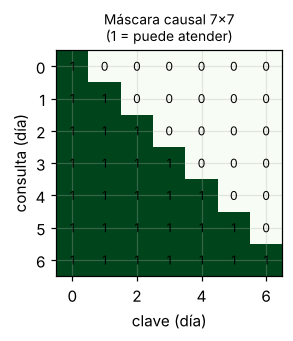

Transformer Encoder-Decoder: params=30209 épocas=46 tiempo=77.6s | MAE test autorregresivo = 1.940 °C (con teacher forcing, no realista: 1.695 °C)


In [8]:
mask_demo = causal_mask(HORIZON)
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(mask_demo, cmap="Greens"); ax.set_title("Máscara causal 7×7\n(1 = puede atender)", fontsize=9)
ax.set_xlabel("clave (día)"); ax.set_ylabel("consulta (día)")
for i in range(HORIZON):
    for j in range(HORIZON): ax.text(j, i, int(mask_demo[i, j]), ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.savefig("figures/03_mascara_causal.png", bbox_inches="tight"); plt.show()

def decoder_inputs(X, Y, F):
    """[temperatura del día anterior, sin, cos del día objetivo] para los 7 pasos (teacher forcing)."""
    prev = np.concatenate([X[:, -1:, 0], Y[:, :-1]], axis=1)
    return np.concatenate([prev[..., None], F], axis=-1).astype("float32")

def build_encdec(n_enc=2, n_dec=1):
    enc_in = keras.Input((LOOKBACK, 3), name="ventana"); dec_in = keras.Input((HORIZON, 3), name="decoder_in")
    e = layers.Dropout(DROPOUT)(PositionalEncoding(LOOKBACK, D_MODEL)(layers.Dense(D_MODEL, name="emb_encoder")(enc_in)))
    for i in range(n_enc):
        e = EncoderBlock(D_MODEL, HEADS, D_FF, DROPOUT, name=f"encoder_{i + 1}")(e)
    d = layers.Dropout(DROPOUT)(PositionalEncoding(HORIZON, D_MODEL)(layers.Dense(D_MODEL, name="emb_decoder")(dec_in)))
    crosses = []
    for i in range(n_dec):
        d, w_self, w_cross = DecoderBlock(D_MODEL, HEADS, D_FF, DROPOUT, name=f"decoder_{i + 1}")(d, e, return_attention=True)
        crosses.append(w_cross)
    out = layers.Reshape((HORIZON,))(layers.Dense(1, name="salida")(d))
    return keras.Model([enc_in, dec_in], out, name="Transformer_Encoder_Decoder"), keras.Model([enc_in, dec_in], crosses[-1])

def autoregressive(model, X, F):
    """Generación paso a paso: la predicción del día t alimenta al decoder en el día t+1."""
    prev = np.zeros((len(X), HORIZON), dtype="float32"); prev[:, 0] = X[:, -1, 0]
    for t in range(HORIZON):
        dec = np.concatenate([prev[..., None], F], axis=-1)
        y = model.predict([X, dec], verbose=0, batch_size=256)
        if t + 1 < HORIZON: prev[:, t + 1] = y[:, t]
    return y

keras.utils.set_random_seed(SEED)
encdec, cross_model = build_encdec()
name = "Transformer Encoder-Decoder"
hists[name], secs = fit(encdec, [Xtr, decoder_inputs(Xtr, Ytr, Ftr)], Ytr, [Xva, decoder_inputs(Xva, Yva, Fva)], Yva)
models[name] = encdec
pred_tf = encdec.predict([Xte, decoder_inputs(Xte, Yte, Fte)], verbose=0)
res[name] = {"val": metrics(Yva, autoregressive(encdec, Xva, Fva), scaler), "test": metrics(Yte, autoregressive(encdec, Xte, Fte), scaler),
             "test_teacher_forcing": metrics(Yte, pred_tf, scaler), "params": encdec.count_params(), "tiempo_s": round(secs, 1),
             "epocas": len(hists[name]["loss"])}
print(f"{name}: params={encdec.count_params()} épocas={res[name]['epocas']} tiempo={secs:.1f}s | MAE test autorregresivo = "
      f"{res[name]['test']['MAE']:.3f} °C (con teacher forcing, no realista: {res[name]['test_teacher_forcing']['MAE']:.3f} °C)")

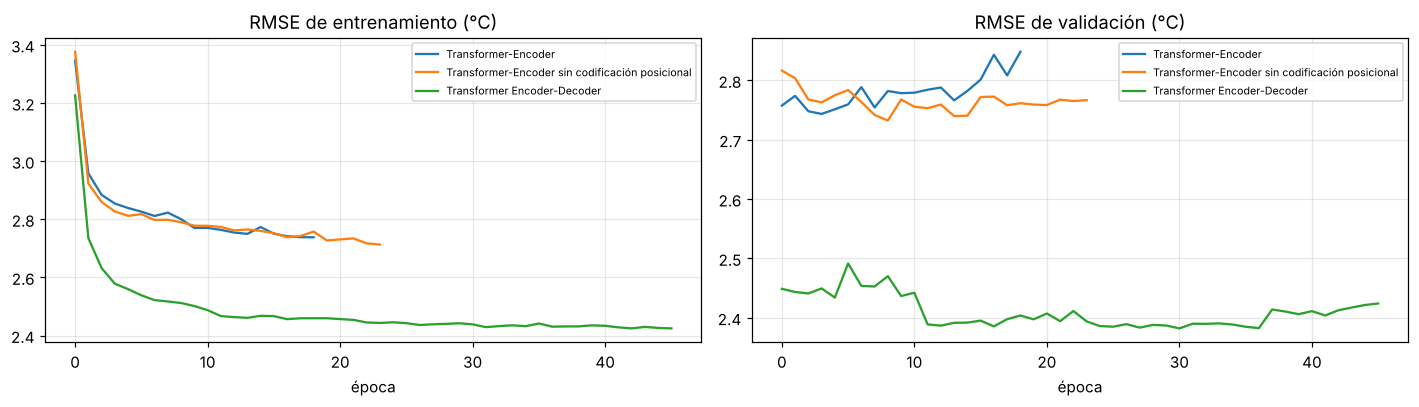

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for n, h in hists.items():
    ax[0].plot(np.sqrt(h["loss"]) * scaler.sigma, label=n); ax[1].plot(np.sqrt(h["val_loss"]) * scaler.sigma, label=n)
ax[0].set_title("RMSE de entrenamiento (°C)"); ax[1].set_title("RMSE de validación (°C)")
for a in ax: a.set_xlabel("época"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("figures/03_entrenamiento.png", bbox_inches="tight"); plt.show()

## 5. Comparación de todos los modelos (test 1989–1990)

In [10]:
prev_res = {}
if os.path.exists("results/01_baselines.json"):
    prev_res.update({k: {"test": v["test"], "params": 0} for k, v in load_json("results/01_baselines.json")["baselines"].items()})
if os.path.exists("results/02_atencion.json"):
    prev_res.update(load_json("results/02_atencion.json")["resultados"])
allres = {**prev_res, **res}
comp = pd.DataFrame({n: {"MAE (°C)": v["test"]["MAE"], "RMSE (°C)": v["test"]["RMSE"], "MAE día 1": v["test"]["MAE_d1"],
                         "MAE día 7": v["test"]["MAE_d7"], "parámetros": v.get("params", 0), "tiempo (s)": v.get("tiempo_s", 0)}
                     for n, v in allres.items()}).T.sort_values("MAE (°C)")
comp.round(3)

,MAE (°C),RMSE (°C),MAE día 1,MAE día 7,parámetros,tiempo (s)
Transformer Encoder-Decoder,1.940,2.492,1.703,1.980,30209.0,77.6
LSTM + atención aditiva,1.981,2.536,1.866,1.992,22471.0,26.0
Transformer-Encoder,1.983,2.538,1.883,2.032,21831.0,25.9
Transformer-Encoder sin codificación posicional,1.987,2.540,1.828,2.012,21831.0,30.3
LSTM,1.987,2.540,1.822,2.011,17863.0,29.1
LSTM + atención producto escalado,1.989,2.549,1.835,2.016,24327.0,32.6
Atención no paramétrica (NumPy),1.990,2.544,1.862,2.027,0.0,0.0
Regresión lineal (Ridge),1.994,2.568,1.765,2.026,0.0,0.0
Climatología,2.024,2.593,2.031,2.014,0.0,0.0
Persistencia,2.624,3.321,1.958,2.750,0.0,0.0


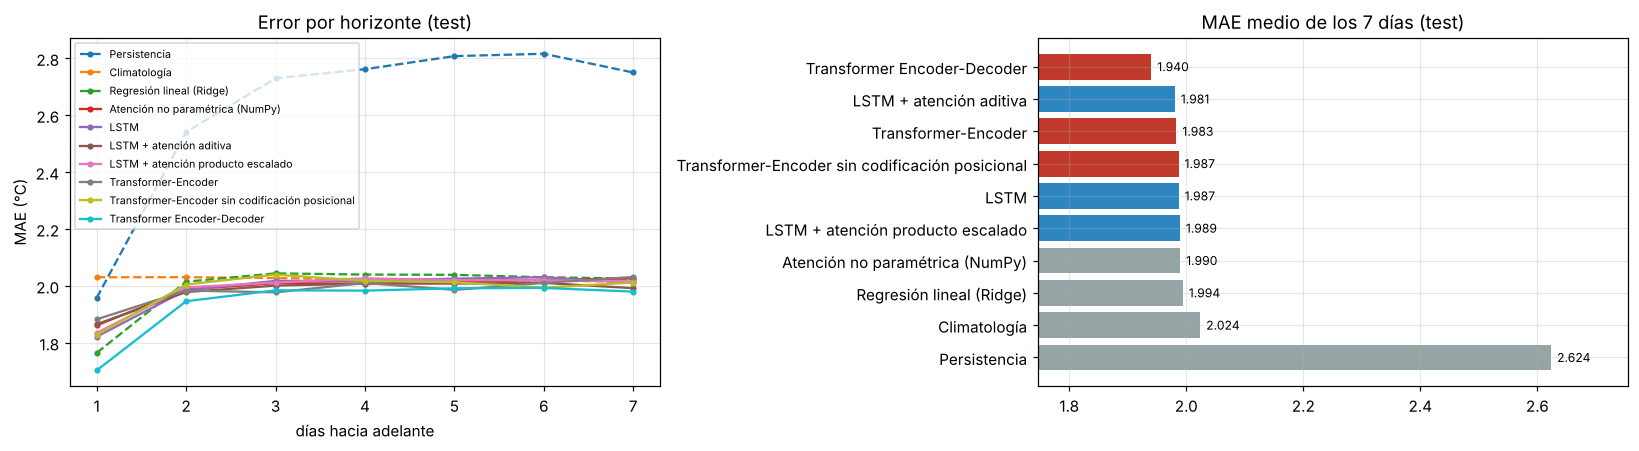

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for n, v in allres.items():
    ls = "--" if n in ("Persistencia", "Climatología", "Regresión lineal (Ridge)") else "-"
    ax[0].plot(range(1, HORIZON + 1), v["test"]["MAE_h"], ls, marker="o", ms=3, label=n)
ax[0].set_xlabel("días hacia adelante"); ax[0].set_ylabel("MAE (°C)"); ax[0].set_title("Error por horizonte (test)"); ax[0].legend(fontsize=7)
c = comp["MAE (°C)"].sort_values(ascending=False)
ax[1].barh(c.index, c.values, color=["#c0392b" if "Transformer" in n else "#2e86c1" if "LSTM" in n else "#95a5a6" for n in c.index])
for i, v in enumerate(c.values): ax[1].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)
ax[1].set_xlim(c.min() * 0.9, c.max() * 1.05); ax[1].set_title("MAE medio de los 7 días (test)")
plt.tight_layout(); plt.savefig("figures/03_comparacion.png", bbox_inches="tight"); plt.show()

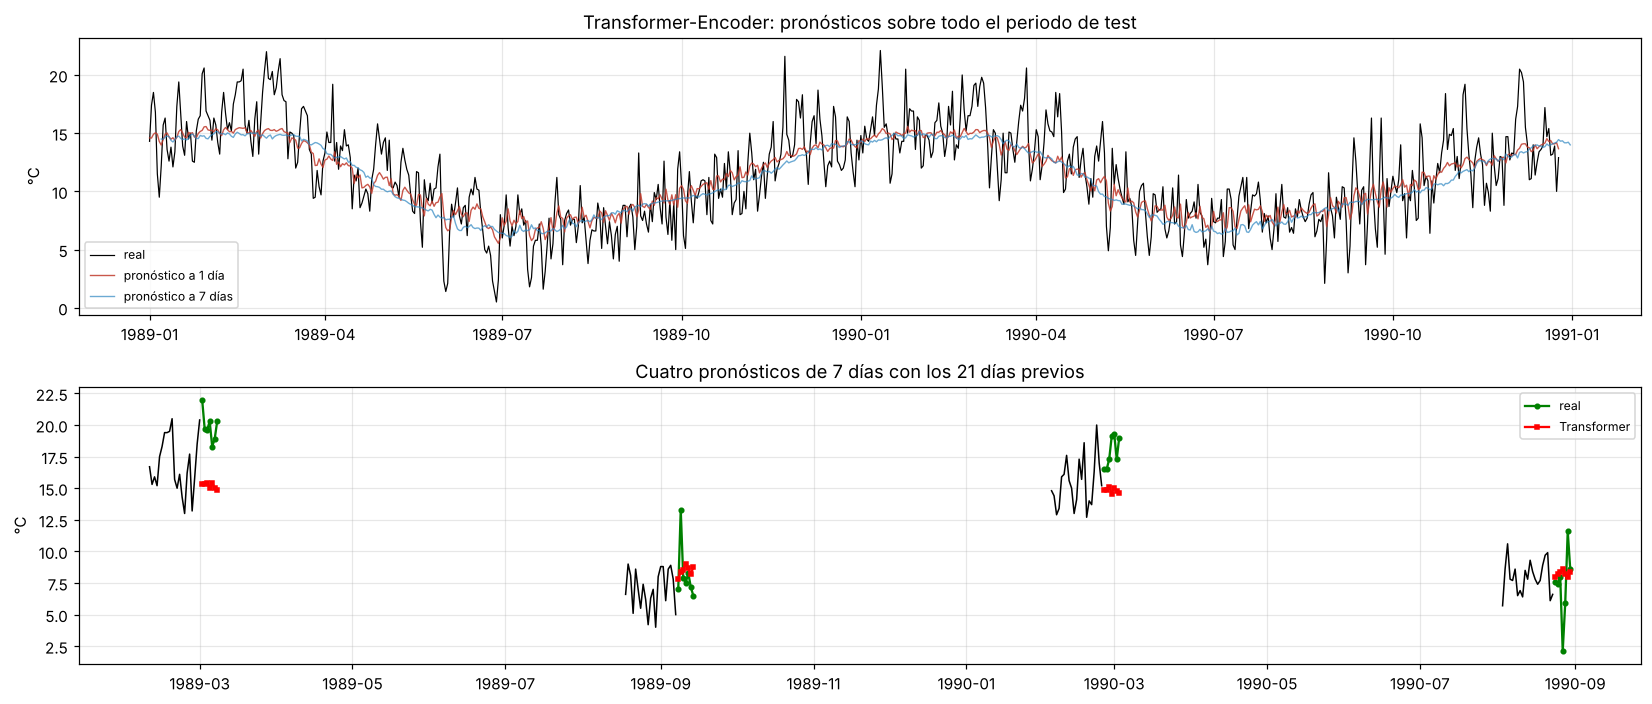

In [12]:
best = "Transformer-Encoder"
P = scaler.inverse(models[best].predict(Xte, verbose=0)); Yt = scaler.inverse(Yte)
dts = pd.to_datetime(data["test"]["dates"])
fig, ax = plt.subplots(2, 1, figsize=(15, 6.5))
ax[0].plot(dts, Yt[:, 0], color="k", lw=0.8, label="real")
ax[0].plot(dts, P[:, 0], color="#c0392b", lw=0.9, alpha=0.85, label="pronóstico a 1 día")
ax[0].plot(dts + pd.Timedelta(days=6), P[:, 6], color="#2e86c1", lw=0.9, alpha=0.7, label="pronóstico a 7 días")
ax[0].set_title(f"{best}: pronósticos sobre todo el periodo de test"); ax[0].legend(fontsize=8); ax[0].set_ylabel("°C")
for k, j in enumerate([60, 250, 420, 600]):
    d0 = dts[j]; past = pd.date_range(end=d0 - pd.Timedelta(days=1), periods=21); fut = pd.date_range(d0, periods=HORIZON)
    ax[1].plot(past, scaler.inverse(Xte[j, -21:, 0]), "k-", lw=1)
    ax[1].plot(fut, Yt[j], "g-o", ms=3, label="real" if k == 0 else None)
    ax[1].plot(fut, P[j], "r-s", ms=3, label="Transformer" if k == 0 else None)
ax[1].set_title("Cuatro pronósticos de 7 días con los 21 días previos"); ax[1].legend(fontsize=8); ax[1].set_ylabel("°C")
plt.tight_layout(); plt.savefig("figures/03_pronosticos.png", bbox_inches="tight"); plt.show()

## 6. Mapas de atención del Transformer
Pesos de self-attention de las 4 cabezas del segundo bloque del encoder para una ventana de test (fila = día que consulta, columna = día consultado), y peso medio que la **última posición** de la ventana (la que más influye en el pronóstico) asigna a cada rezago, promediado sobre todo el test.

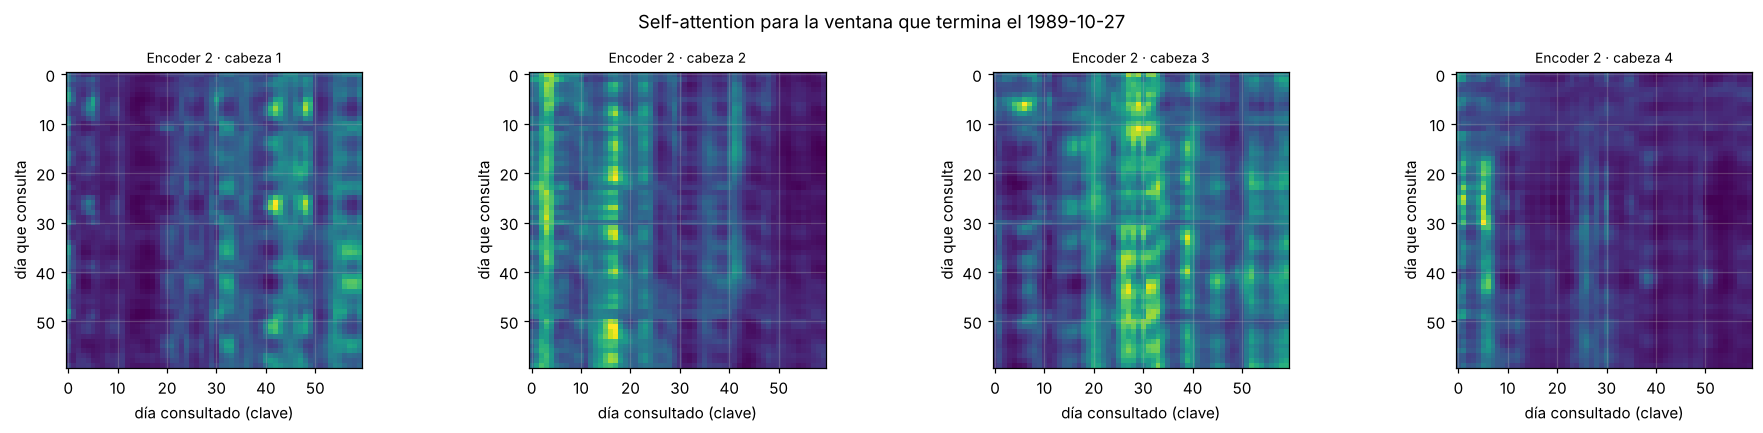

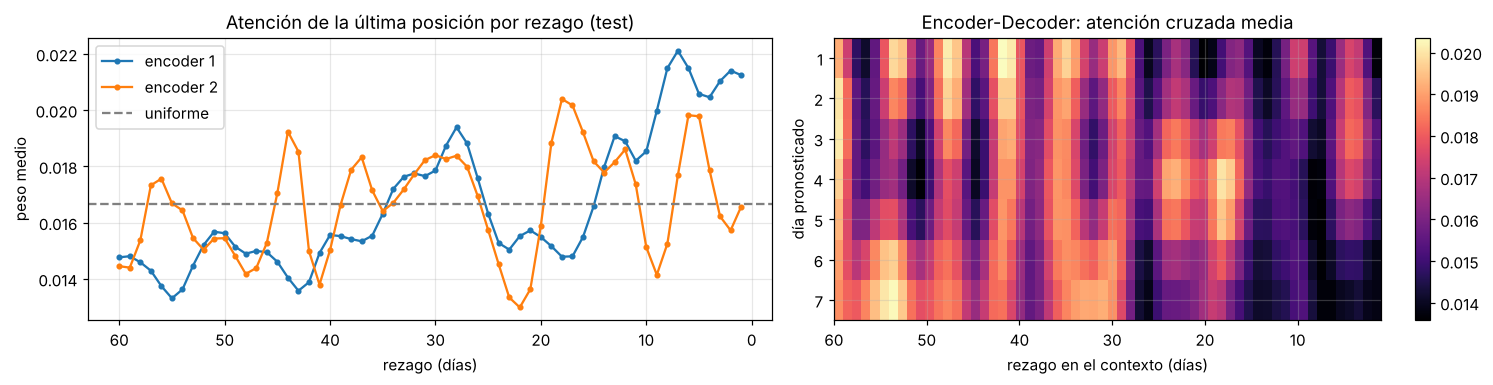

Fracción de la atención de la última posición en los últimos 7 días, por capa: [0.148 0.124] (uniforme = 0.117)


In [13]:
j = 300
atts = att_models["Transformer-Encoder"].predict(Xte[j:j + 1], verbose=0)
fig, axes = plt.subplots(1, HEADS, figsize=(17, 3.9))
for hd in range(HEADS):
    axes[hd].imshow(atts[-1][0, hd], cmap="viridis"); axes[hd].set_title(f"Encoder 2 · cabeza {hd + 1}", fontsize=9)
    axes[hd].set_xlabel("día consultado (clave)"); axes[hd].set_ylabel("día que consulta")
plt.suptitle(f"Self-attention para la ventana que termina el {str(pd.Timestamp(data['test']['dates'][j]) - pd.Timedelta(days=1))[:10]}")
plt.tight_layout(); plt.savefig("figures/03_mapas_atencion.png", bbox_inches="tight"); plt.show()

A_all = att_models["Transformer-Encoder"].predict(Xte, verbose=0, batch_size=256)
last_q = np.stack([a[:, :, -1, :].mean(1) for a in A_all])          # (capas, ventanas, claves)
lag = np.arange(LOOKBACK, 0, -1)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for l in range(len(A_all)):
    ax[0].plot(lag, last_q[l].mean(0), marker=".", label=f"encoder {l + 1}")
ax[0].axhline(1 / LOOKBACK, ls="--", c="gray", label="uniforme"); ax[0].invert_xaxis()
ax[0].set_xlabel("rezago (días)"); ax[0].set_ylabel("peso medio"); ax[0].set_title("Atención de la última posición por rezago (test)"); ax[0].legend()
cross = cross_model.predict([Xte, decoder_inputs(Xte, Yte, Fte)], verbose=0, batch_size=256).mean(axis=(0, 1))   # (7, 60)
im = ax[1].imshow(cross, aspect="auto", cmap="magma", extent=[LOOKBACK, 1, HORIZON + 0.5, 0.5])
ax[1].set_xlabel("rezago en el contexto (días)"); ax[1].set_ylabel("día pronosticado"); ax[1].set_title("Encoder-Decoder: atención cruzada media")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.savefig("figures/03_atencion_rezagos.png", bbox_inches="tight"); plt.show()
share7 = [float(last_q[l][:, -7:].sum(1).mean()) for l in range(len(A_all))]
print("Fracción de la atención de la última posición en los últimos 7 días, por capa:", np.round(share7, 3), "(uniforme = 0.117)")

In [14]:
for n in ("Transformer-Encoder", "Transformer Encoder-Decoder"):
    models[n].save(f"modelos/{models[n].name}.keras")
save_json({"resultados": res, "comparacion": comp.reset_index(names="modelo").to_dict("records"), "atencion_ultimos7": share7,
           "verificacion_mha": float(np.abs(np.array(out_mine) - np.array(out_ref)).max()), "historias": hists}, "results/03_transformer.json")

## 7. Análisis y conclusiones
* **Implementación verificada:** la multi-head attention propia reproduce la capa oficial de Keras con una diferencia máxima de 3.6·10⁻⁷ en la salida y 1.8·10⁻⁷ en los pesos de atención.
* **Mejor modelo: Transformer Encoder-Decoder**, con MAE test 1.940 °C, RMSE 2.49 °C y **1.70 °C en el día 1**. Es el único que supera claramente a todas las referencias (regresión lineal: 1.994 / 1.77 °C) y a los LSTM (1.98–1.99 °C), con sólo 30 209 parámetros y unos 78 s de entrenamiento en CPU. Su ventaja viene de la **atención cruzada** y de la generación autorregresiva: cada día pronosticado consulta el contexto y la predicción del día anterior.
* *Teacher forcing* vs. inferencia real: con los valores reales como entrada del decoder el MAE sería 1.70 °C, pero ese escenario no es posible en producción. El valor honesto es el autorregresivo (1.94 °C), porque los errores se propagan de un día al siguiente.
* El **Transformer-Encoder** (1.983 °C) iguala a los LSTM con un número de parámetros parecido (21 831 frente a 17 863–24 327) y procesa los 60 días en paralelo en lugar de secuencialmente.
* **Ablación de la codificación posicional:** quitarla apenas cambia el MAE (1.987 frente a 1.983 °C). En esta ventana las variables de calendario (sin, cos del día del año) varían suavemente a lo largo de los 60 días y ya funcionan como una señal de posición. Sin ellas, la self-attention sería invariante al orden y la codificación posicional sería imprescindible.
* **Mapas de atención:** cada cabeza se especializa en días concretos de la ventana (franjas verticales), y la primera capa concentra el 14.8 % de la atención de la última posición en la última semana, frente al 11.7 % uniforme. La atención cruzada del decoder reparte su peso de forma distinta según el día pronosticado.
* **Límite del problema:** con temperatura y calendario como únicas entradas, los días 3 a 7 son poco predecibles (todos los modelos rondan 2.0 °C, cerca de la climatología). Para mejorar habría que añadir variables meteorológicas (presión, viento, humedad), no más capacidad del modelo.